In [39]:
def prep_for_modelling (fp, remove_events_with_zero_flooding):
    
    ### Get event data
    rainfall_events_all_df = pd.read_pickle(fp)
    # Get rid of unphysical values
    rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
    # Add length variables, remove length '1' events
    rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")
    rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['length_of_active_rain']>1].copy()
    # Add random variable
    rainfall_events_all_df['random_variable'] = np.random.normal(size=len(rainfall_events_all_df))

    # Set NAN values to 0 (as they should represent the same thing)
    rainfall_events_all_df[['peak_cell_outflow_N', 
                            'peak_cell_outflow_S', 'peak_cell_outflow_E','peak_cell_outflow_W']]=rainfall_events_all_df[[
        'peak_cell_outflow_N', 'peak_cell_outflow_S', 'peak_cell_outflow_E','peak_cell_outflow_W']].fillna(value=0)

    for level in ['t50', 't60', 't80']:
        rainfall_events_all_df[f'cluster_mean_intensity_{level}'] = (
            rainfall_events_all_df[f'cluster_rain_total_{level}'] / rainfall_events_all_df[f'cluster_n_cells_{level}'].replace(0, np.nan))    

    # Remove variables which carry no meaning
    variables = list(rainfall_events_all_df.columns)
    to_be_removed = {'x_coord', 'y_coord',
                    'x_idx', 'y_idx', 'x_idx_global', "y_idx_global", 't_global','t_local', "day_360", "month",
                     "max_precip_from_csv", "event_num", "time_mismatch", "ens",  'start_idx', 'stop_idx',
                     "t_local_rebased", "times", "values", "mismatch", 'n_valid', 'pct_over1', 'pct_under0',
                    # "10cm_volume", "30cm_area", "30cm_volume", "10cm_area", 
                    'mean_sm_3_before_event', 
                     'mean_sm_4_before_event', 'mean_sm_5_before_event', 'neighbourhood_flood_10_area',
                     'neighbourhood_flood_10_vol', 'neighbourhood_flood_30_area', 'neighbourhood_flood_30_vol',
                    'threshold_flood_10_area_t50', 'cluster_flood_10_area_t50',  'threshold_flood_10_vol_t50',
                     'cluster_flood_10_vol_t50', 'threshold_flood_30_area_t50', 'cluster_flood_30_area_t50',
                     'threshold_flood_30_vol_t50','cluster_flood_30_vol_t50','threshold_flood_10_area_t60',
                     'cluster_flood_10_area_t60','threshold_flood_10_vol_t60','cluster_flood_10_vol_t60',
                     'threshold_flood_30_area_t60','cluster_flood_30_area_t60','threshold_flood_30_vol_t60',
                     'cluster_flood_30_vol_t60','threshold_flood_10_area_t80', 'cluster_flood_10_area_t80',
                     'threshold_flood_10_vol_t80', 'cluster_flood_10_vol_t80', 'threshold_flood_30_area_t80',
                     'cluster_flood_30_area_t80', 'threshold_flood_30_vol_t80','cluster_flood_30_vol_t80', 
                     'event_num.1', 'date','Unnamed: 0', 'peak_cell_id',"rainfall_peak_day", "catchment_num",
                     'peak_cell_edge_truncated_N', 'peak_cell_edge_truncated_S', 'peak_cell_edge_truncated_E',
                     'peak_cell_edge_truncated_W',"peak_cell_near_catchment_boundary",
                     'total_acc_n'
                     #'se_min', 'se_max'
                    }

    rainfall_events_all_df = rainfall_events_all_df.drop(columns=to_be_removed, errors='ignore').copy()
    
    if remove_events_with_zero_flooding == True:
        rainfall_events_all_df=rainfall_events_all_df[rainfall_events_all_df['10cm_area']>0.1]
        
    return rainfall_events_all_df
    
def create_subset (df, sample_size):
    
    ### Get smaller subset for fitting the model quicker (for testing)
    df= df.sample(n=sample_size, random_state=12)  # adjust size to something that runs in seconds
    df.reset_index(inplace=True, drop=True)
    
    return df    

# Feature selection

XXXXXXXXXXXXX

In [3]:
import pandas as pd
import numpy as np
from scipy.stats import zscore, linregress
import matplotlib.pyplot as plt
import sys
import geopandas as gpd
import statsmodels.formula.api as smf
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score, KFold, cross_val_predict, cross_validate
from sklearn.linear_model import LinearRegression
import shap
import seaborn as sns
from scipy.stats import gaussian_kde


sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENT_LOOKUP_DICT, ENSEMBLE_MEMBERS, CATCHMENTS

### Get smaller subset for fitting the model quicker (for testing)

In [35]:
df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl", 
                        remove_events_with_zero_flooding = False)
df[df['mean_sm_2_before_event'].isnull()][["max_precip", "start_year", "hydro_day_360", "max_quartile_index_n", "length", "total_acc", "length_of_active_rain"]]
print(len(df))
df = df.dropna().copy()
print(len(df))
df = create_subset(df, 5000)

104983
104970


### Create model instances

In [36]:
rf = RandomForestRegressor(n_estimators=100,max_depth=8,random_state=42)
lr = LinearRegression()
cv_parameters = KFold(n_splits=5, shuffle=True, random_state=42)
error_metrics = ['neg_mean_absolute_error', 'r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_percentage_error']

### Plus descriptors of temporal rainfall profile

In [40]:
predictor_variables = ['max_precip', 'total_acc',
                       'peak_position_ratio_n','d50_n','gini_n','time_based_std_n','dry_ratio_n', 'max_quartile_index_n',
                       'peak_position_ratio','d50','gini','time_based_std','dry_ratio', 'max_quartile_index',
                       "length_of_active_rain", "length", 
                       'cluster_rain_total_t50', 'cluster_n_cells_t50', 
                       'cluster_rain_total_t60',  'cluster_n_cells_t60',
                     'cluster_rain_total_t80', 'cluster_n_cells_t80',
                      "mean_sm_2_before_event", ]

X = df[predictor_variables]
y = df['10cm_area']

baseline_r2_lr = cross_val_score(lr, X, y, cv=cv_parameters, scoring='r2').mean()
print(f"Linear regression R²: {baseline_r2_lr:.4f}")

baseline_r2_rf = cross_val_score(rf, X, y, cv=cv_parameters, scoring='r2').mean()
print(f"Random forest R²:     {baseline_r2_rf:.4f}")

Linear regression R²: 0.1508
Random forest R²:     0.1724


In [41]:
rf.fit(X,y)
explainer = shap.TreeExplainer(rf)

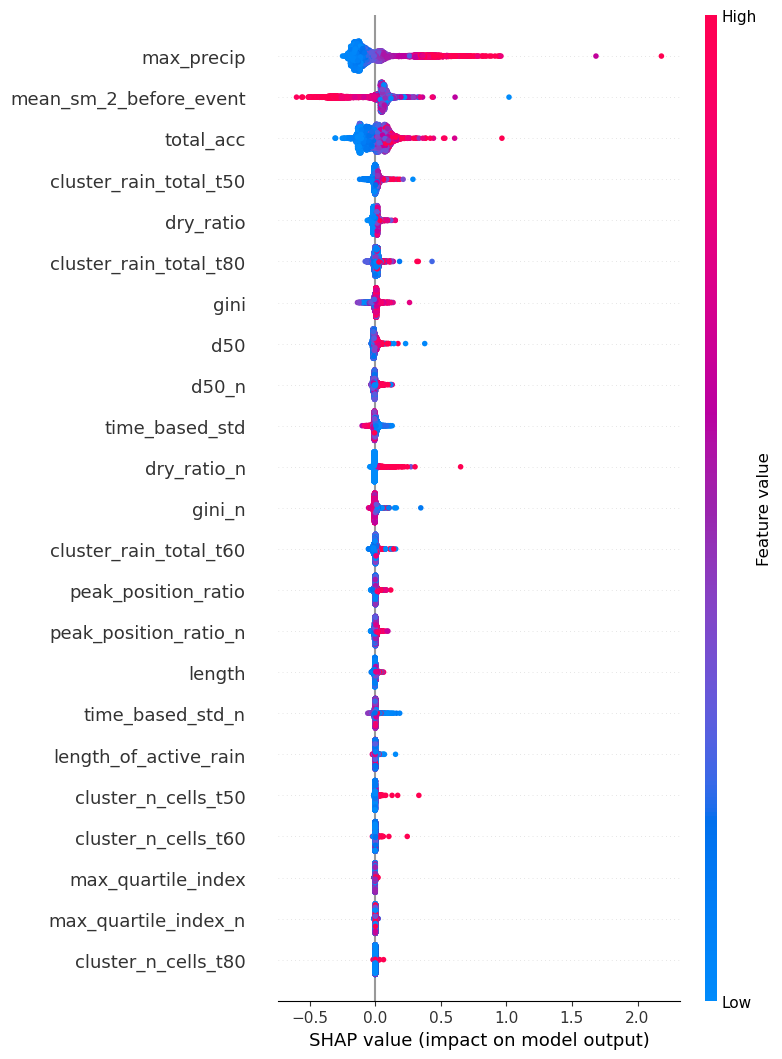

In [43]:
shap_values = explainer.shap_values(X)

# Global summary: which variables matter most overall, and in which direction
shap.summary_plot(shap_values, X, show=True, max_display=50)

In [44]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# 1. Fit once on everything (same logic as your earlier stationarity work -
#    one fixed model, evaluated differently per period, not refit per period)
# ------------------------------------------------------------------
# rf.fit(X, y)
# explainer = shap.TreeExplainer(rf)
# shap_values = explainer.shap_values(X)  # shape: (n_samples, n_features)

# Attach SHAP values back to a results dataframe alongside period info
results = X.copy()
results['start_year'] = df['start_year'].values  # adjust to however you derive year
for i, var in enumerate(X.columns):
    results[f'shap_{var}'] = shap_values[:, i]

# ------------------------------------------------------------------
# 2. Pick the structure variables you want to track
# ------------------------------------------------------------------
structure_vars = ['gini', 'peak_position_ratio', 'cluster_n_cells_t60', 'time_based_std', "d50_n", "mean_sm_2_before_event"]
# adjust names to match your current, consolidated predictor set

periods = {
    'Early (1980-2013)': (1980, 2013),
    'Mid (2014-2046)':   (2014, 2046),
    'Late (2047-2080)':  (2047, 2080),
}

# ------------------------------------------------------------------
# 3. Compute mean |SHAP value| per variable, per period
# ------------------------------------------------------------------
importance_by_period = {var: [] for var in structure_vars}

for label, (y0, y1) in periods.items():
    mask = (results['start_year'] >= y0) & (results['start_year'] <= y1)
    for var in structure_vars:
        mean_abs_shap = results.loc[mask, f'shap_{var}'].abs().mean()
        importance_by_period[var].append(mean_abs_shap)

importance_df = pd.DataFrame(importance_by_period, index=list(periods.keys()))
print(importance_df)

                       gini  peak_position_ratio  cluster_n_cells_t60  \
Early (1980-2013)  0.009502             0.005275             0.001940   
Mid (2014-2046)    0.012331             0.006456             0.002030   
Late (2047-2080)   0.012079             0.006794             0.002251   

                   time_based_std     d50_n  mean_sm_2_before_event  
Early (1980-2013)        0.009101  0.010700                0.073510  
Mid (2014-2046)          0.011062  0.011922                0.097558  
Late (2047-2080)         0.010594  0.011292                0.108737  


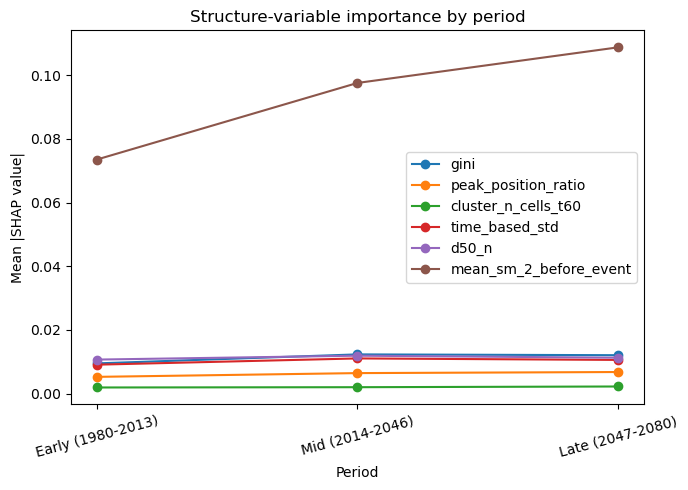

In [45]:
fig, ax = plt.subplots(figsize=(7, 5))

for var in structure_vars:
    ax.plot(importance_df.index, importance_df[var], marker='o', label=var)

ax.set_ylabel('Mean |SHAP value|')
ax.set_xlabel('Period')
ax.set_title('Structure-variable importance by period')
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

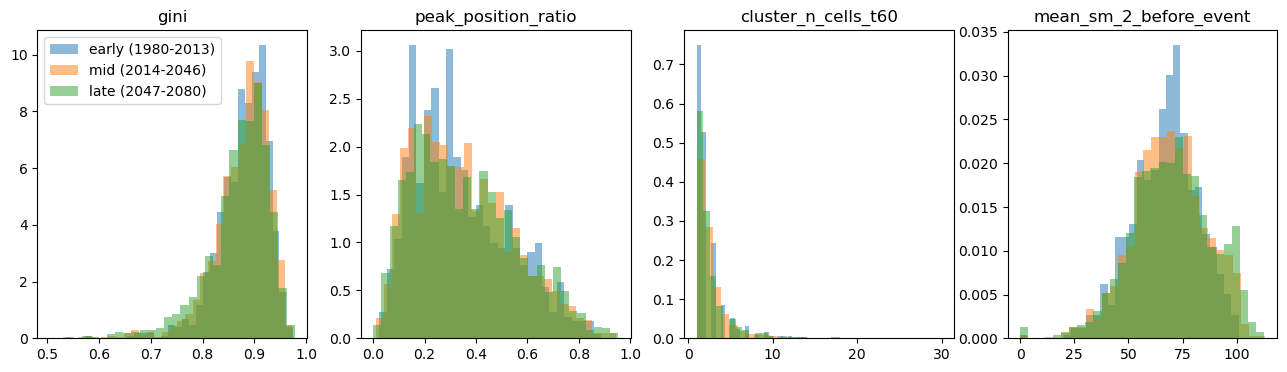

In [47]:
periods = {
    'early (1980-2013)': (1980, 2013),
    'mid (2014-2046)':   (2014, 2046),
    'late (2047-2080)':  (2047, 2080),
}

fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, var in zip(axes, ['gini', 'peak_position_ratio', 'cluster_n_cells_t60',  "mean_sm_2_before_event"]):
    for label, (y0,y1) in periods.items():
        mask = (df['start_year']>=y0)&(df['start_year']<=y1)
        ax.hist(df.loc[mask, var], bins=30, density=True, alpha=0.5, label=label)
    ax.set_title(var)
axes[0].legend()